# EduPredict AI — Day 2: Exploratory Data Analysis and Visualization

**Goal:** Visually and statistically explore both the **Mathematics** (`student-mat.csv`) and **Portuguese** (`student-por.csv`) UCI Student Performance datasets using Pandas, NumPy, Matplotlib, and Seaborn.

> **Important Rules for Day 2:**
> - Original datasets in `data/raw/` are loaded read-only and never modified.
> - All generated figures are saved to `artifacts/figures/`.
> - No machine learning models are trained yet.

## 1. Setup and Load Both Datasets
We import our analysis and plotting libraries, configure a clean Seaborn visual theme, and load both original UCI datasets using `sep=";"`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Consistent, clean visual styling for all charts
sns.set_theme(style="whitegrid", context="notebook")

# Resolve project root regardless of whether notebook runs from root or notebooks/
cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
RAW_DIR = PROJECT_ROOT / "data" / "raw"
FIGURES_DIR = PROJECT_ROOT / "artifacts" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Load original datasets (read-only)
df_math = pd.read_csv(RAW_DIR / "student-mat.csv", sep=";")
df_por = pd.read_csv(RAW_DIR / "student-por.csv", sep=";")

print(f"Mathematics shape: {df_math.shape} | Missing values: {int(df_math.isnull().sum().sum())}")
print(f"Portuguese shape : {df_por.shape} | Missing values: {int(df_por.isnull().sum().sum())}")
print(f"Figures will be saved to: {FIGURES_DIR}")

Matplotlib is building the font cache; this may take a moment.


Mathematics shape: (395, 33) | Missing values: 0
Portuguese shape : (649, 33) | Missing values: 0
Figures will be saved to: artifacts/figures


In [2]:
print("--- Mathematics: First 3 rows ---")
display(df_math.head(3))

print("--- Portuguese: First 3 rows ---")
display(df_por.head(3))

--- Mathematics: First 3 rows ---


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10


--- Portuguese: First 3 rows ---


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12


## 2. Histograms for Final Grades (`G3`)
We plot the distribution of final grades (`G3`, on a `0–20` scale) for both subjects, adding:
- A dashed **blue/green** line for the **mean** and a solid line for the **median**
- A red dotted line at **`G3 = 10`**, which is the standard passing threshold in the Portuguese school system.

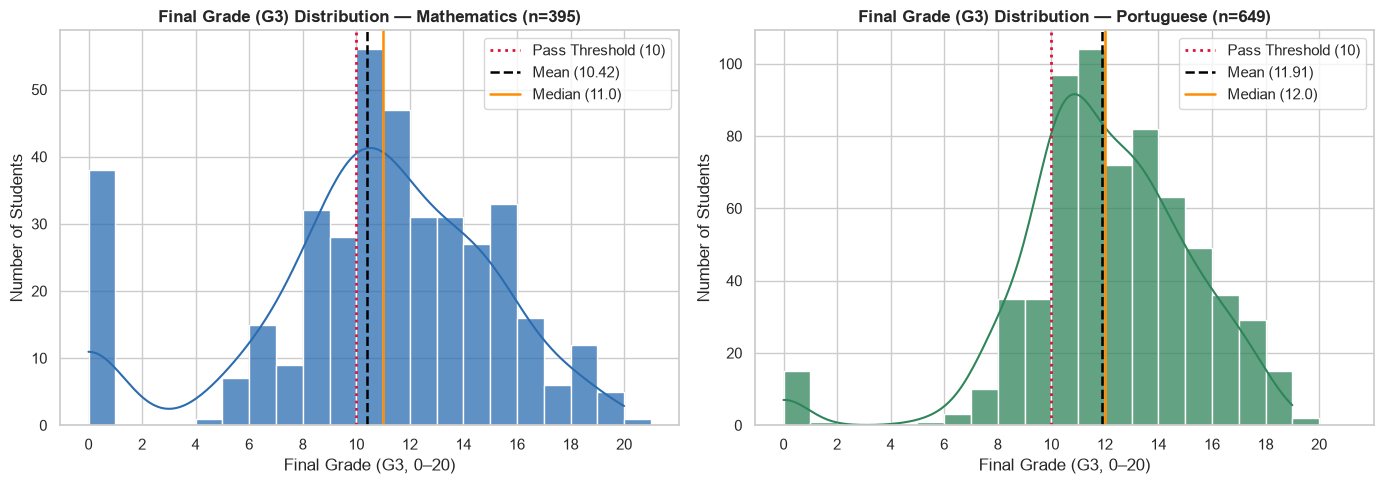

Saved: 01_final_grades_histogram.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

datasets = [
    ("Mathematics (n=395)", df_math, "#2b6cb0"),
    ("Portuguese (n=649)", df_por, "#2f855a"),
]

for ax, (title, df, color) in zip(axes, datasets):
    sns.histplot(df["G3"], bins=21, binrange=(0, 21), kde=True, color=color, alpha=0.75, ax=ax)
    mean_val = df["G3"].mean()
    median_val = df["G3"].median()

    ax.axvline(10, color="crimson", linestyle=":", linewidth=2, label="Pass Threshold (10)")
    ax.axvline(mean_val, color="black", linestyle="--", linewidth=1.8, label=f"Mean ({mean_val:.2f})")
    ax.axvline(median_val, color="darkorange", linestyle="-", linewidth=1.8, label=f"Median ({median_val:.1f})")

    ax.set_title(f"Final Grade (G3) Distribution — {title}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Final Grade (G3, 0–20)")
    ax.set_ylabel("Number of Students")
    ax.set_xticks(range(0, 21, 2))
    ax.legend()

plt.tight_layout()
hist_path = FIGURES_DIR / "01_final_grades_histogram.png"
plt.savefig(hist_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {hist_path.name}")

### Observations — Final Grade Histograms (`01_final_grades_histogram.png`)
1. **Zero-grade spike in Mathematics:** `38` students in Mathematics (`9.6%`) received a final grade of `G3 = 0`, creating a clear bimodal spike at `0`. In Portuguese, only `15` students (`2.3%`) scored `0`.
2. **Higher and tighter scores in Portuguese:** Portuguese grades cluster more tightly around the center (`mean = 11.91`, `median = 12.0`, `std = 3.23`) compared to Mathematics (`mean = 10.42`, `median = 11.0`, `std = 4.58`).
3. **Pass threshold (`G3 >= 10`):** A visibly larger share of Portuguese students (`84.59%`) sit at or above `10` compared to Mathematics (`67.09%`).

## 3. Boxplots for Numerical Features
Because the 16 numeric columns have very different scales (`1–5` survey scales vs `0–20` grades vs `0–75` absences), plotting them in three grouped panels keeps every feature readable and makes outliers easy to spot.

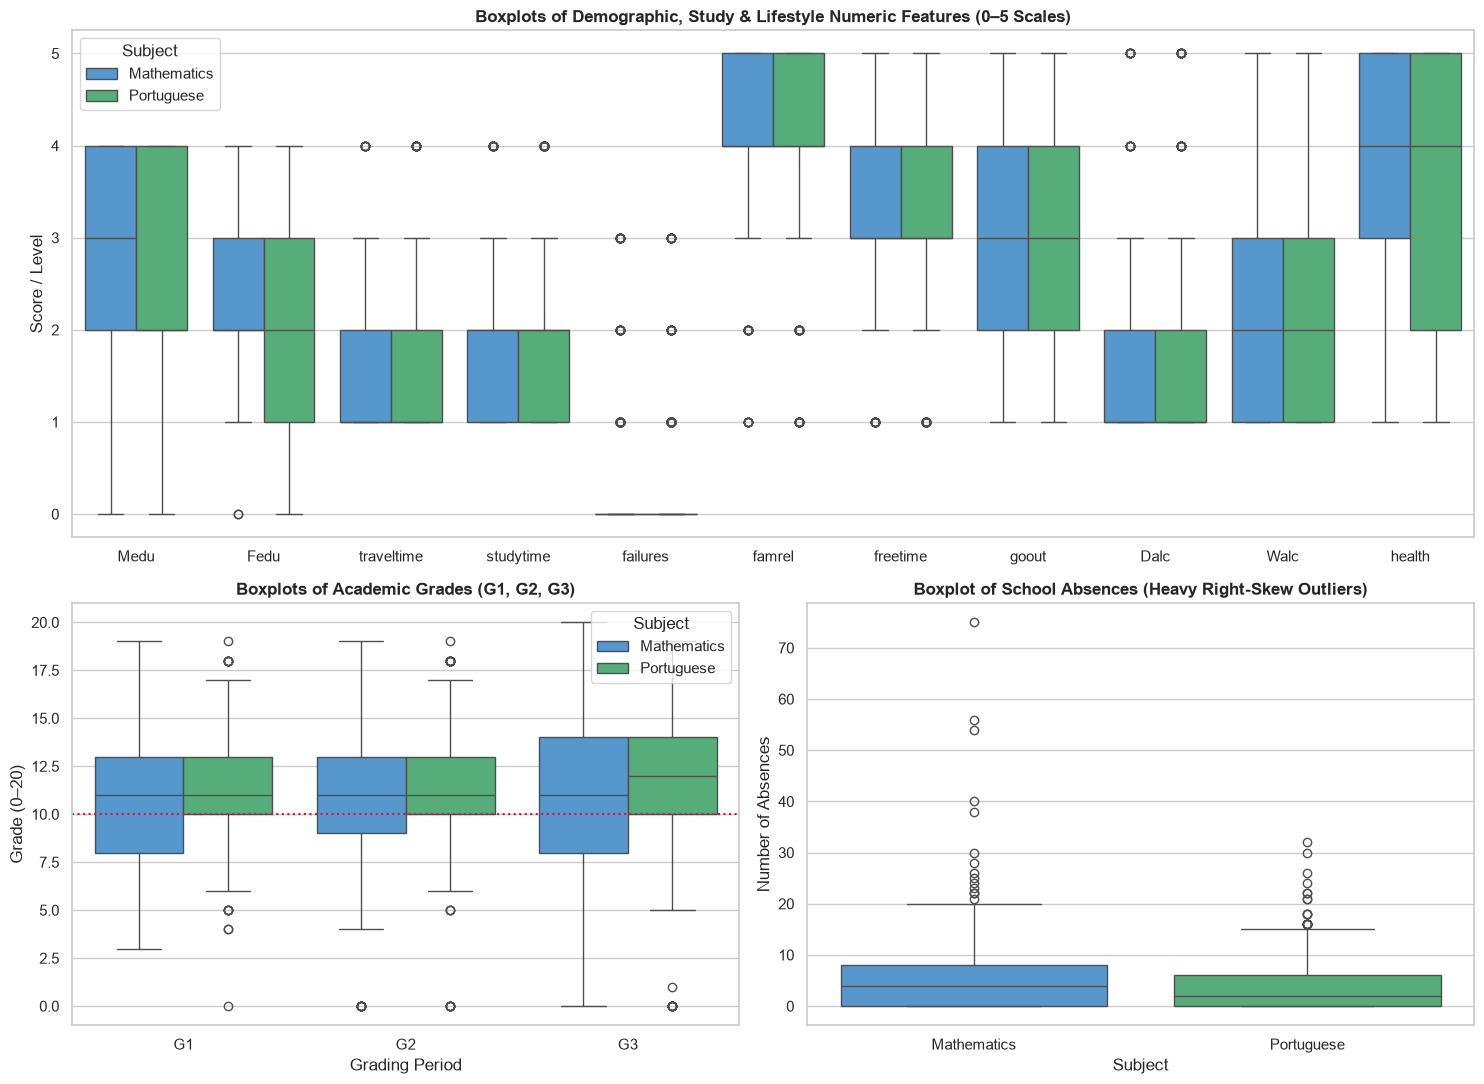

Saved: 02_numerical_features_boxplots.png


In [4]:
# Combine copies in memory only for grouped plotting
df_plot = pd.concat([
    df_math.assign(Subject="Mathematics"),
    df_por.assign(Subject="Portuguese")
], ignore_index=True)

scale_cols = ["Medu", "Fedu", "traveltime", "studytime", "failures",
              "famrel", "freetime", "goout", "Dalc", "Walc", "health"]
grade_cols = ["G1", "G2", "G3"]

fig = plt.figure(figsize=(15, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1.2, 1])

# Panel 1: Survey / Ordinal numeric features (top spanning both columns)
ax1 = fig.add_subplot(gs[0, :])
melted_scale = df_plot.melt(id_vars="Subject", value_vars=scale_cols, var_name="Feature", value_name="Value")
sns.boxplot(data=melted_scale, x="Feature", y="Value", hue="Subject", palette=["#4299e1", "#48bb78"], ax=ax1)
ax1.set_title("Boxplots of Demographic, Study & Lifestyle Numeric Features (0–5 Scales)", fontsize=12, fontweight="bold")
ax1.set_xlabel("")
ax1.set_ylabel("Score / Level")
ax1.legend(title="Subject")

# Panel 2: Grades G1, G2, G3
ax2 = fig.add_subplot(gs[1, 0])
melted_grades = df_plot.melt(id_vars="Subject", value_vars=grade_cols, var_name="Period", value_name="Grade")
sns.boxplot(data=melted_grades, x="Period", y="Grade", hue="Subject", palette=["#4299e1", "#48bb78"], ax=ax2)
ax2.axhline(10, color="crimson", linestyle=":", linewidth=1.5, label="Pass (10)")
ax2.set_title("Boxplots of Academic Grades (G1, G2, G3)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Grading Period")
ax2.set_ylabel("Grade (0–20)")

# Panel 3: Absences (and Age inset note)
ax3 = fig.add_subplot(gs[1, 1])
sns.boxplot(data=df_plot, x="Subject", y="absences", hue="Subject", palette=["#4299e1", "#48bb78"], legend=False, ax=ax3)
ax3.set_title("Boxplot of School Absences (Heavy Right-Skew Outliers)", fontsize=12, fontweight="bold")
ax3.set_xlabel("Subject")
ax3.set_ylabel("Number of Absences")

plt.tight_layout()
box_path = FIGURES_DIR / "02_numerical_features_boxplots.png"
plt.savefig(box_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {box_path.name}")

### Observations — Numerical Feature Boxplots (`02_numerical_features_boxplots.png`)
1. **Consistent background distributions:** Survey features (`Medu`, `Fedu`, `traveltime`, `studytime`, `famrel`, `freetime`, `goout`, `Dalc`, `Walc`, `health`) share nearly identical medians and IQRs across both courses.
2. **Zero-inflated `failures`:** Because at least 75% of students have `0` past failures (`Q1 = 0, Q3 = 0`), every student with `1–3` past failures is flagged as an IQR outlier (`83` in Math, `100` in Portuguese).
3. **Wider grade spread & lower outliers in grades:** Mathematics grades (`G1`, `G2`, `G3`) span more widely toward `0`, whereas Portuguese grades have higher medians (`11–12`) with low-end outliers (`G1` below `5.5`, `G3` below `4.0`).
4. **Severe `absences` outliers:** Absences are heavily right-skewed, reaching up to `75` absences in Math (`15` IQR outliers above `20`) and `32` in Portuguese (`21` IQR outliers above `15`).

## 4. Correlation Heatmaps (Seaborn)
We compute the Pearson correlation matrix across all 16 numeric features for both Mathematics and Portuguese and visualize them side by side.

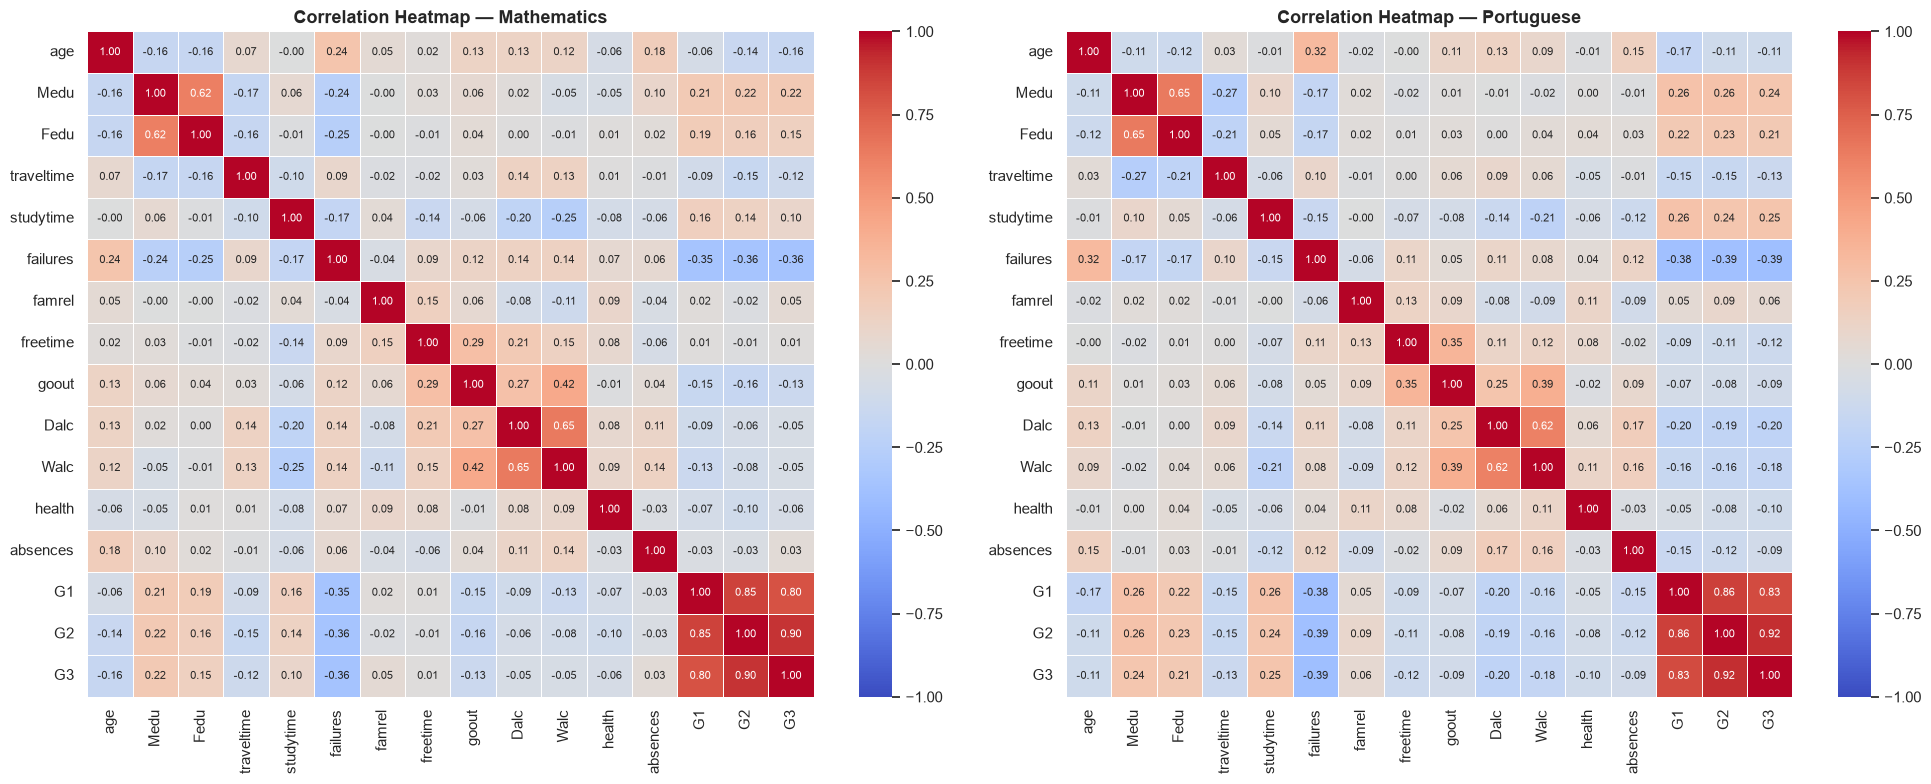

Saved: 03_correlation_heatmaps.png


In [5]:
num_cols = df_math.select_dtypes(include=[np.number]).columns.tolist()
corr_math = df_math[num_cols].corr()
corr_por = df_por[num_cols].corr()

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sns.heatmap(corr_math, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, linewidths=0.5, annot_kws={"size": 8}, ax=axes[0])
axes[0].set_title("Correlation Heatmap — Mathematics", fontsize=13, fontweight="bold")

sns.heatmap(corr_por, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, linewidths=0.5, annot_kws={"size": 8}, ax=axes[1])
axes[1].set_title("Correlation Heatmap — Portuguese", fontsize=13, fontweight="bold")

plt.tight_layout()
heatmap_path = FIGURES_DIR / "03_correlation_heatmaps.png"
plt.savefig(heatmap_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {heatmap_path.name}")

### Observations — Correlation Heatmaps (`03_correlation_heatmaps.png`)
1. **Prior grades dominate `G3`:** `G2` (`r = 0.91` Math, `0.92` Portuguese) and `G1` (`r = 0.80` Math, `0.83` Portuguese) are by far the strongest positive predictors of the final grade `G3`.
2. **Past `failures` hurt final grades:** `failures` has the strongest negative correlation with `G3` (`-0.36` in Math, `-0.39` in Portuguese) as well as with `G1` and `G2`.
3. **Parent education cluster (`Medu` & `Fedu`):** Mother's and father's education are strongly correlated with each other (`r ≈ 0.62–0.65`) and modestly positively correlated with grades (`Medu` vs `G3`: `0.22` Math, `0.24` Portuguese).
4. **Lifestyle cluster (`Dalc`, `Walc`, `goout`):** Workday and weekend alcohol consumption correlate strongly (`r ≈ 0.62–0.65`), and both correlate with going out (`goout`) and negatively with `studytime`.

## 5. Scatter Plots for `G1`, `G2`, and `G3`
We inspect pairwise relationships between first-period (`G1`), second-period (`G2`), and final (`G3`) grades across both subjects with linear trend lines.

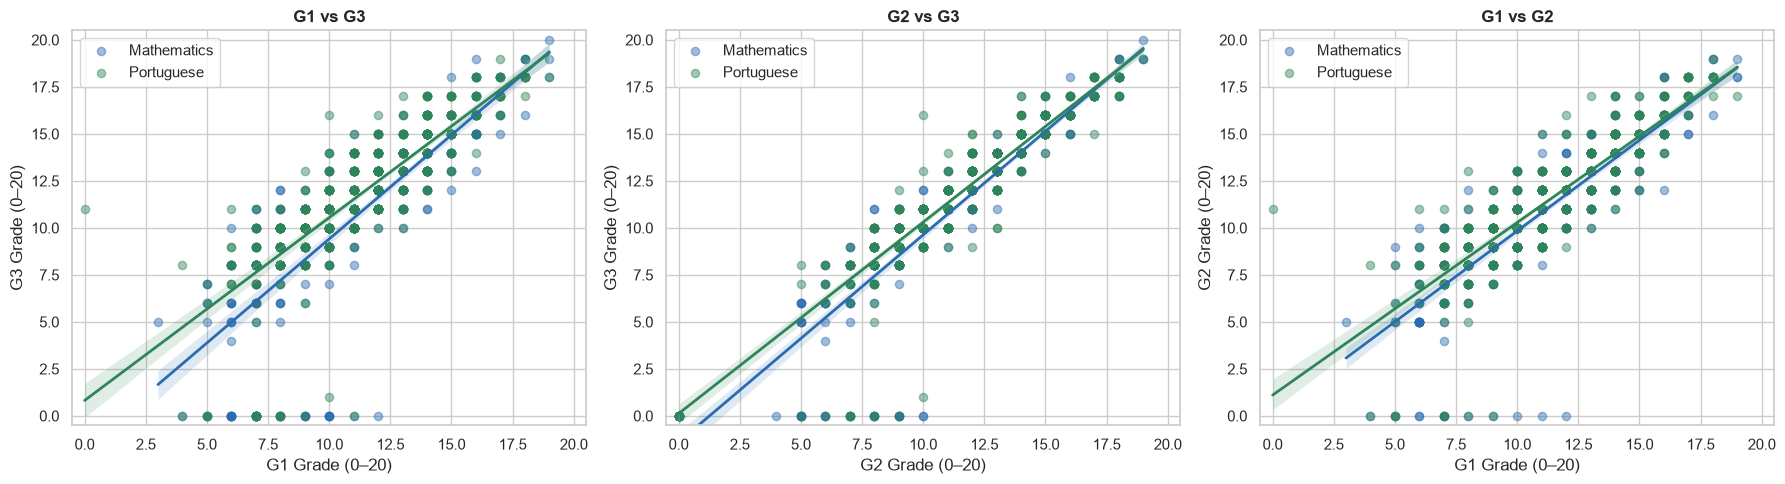

Saved: 04_grades_scatter_plots.png


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
pairs = [("G1", "G3"), ("G2", "G3"), ("G1", "G2")]

for ax, (x_col, y_col) in zip(axes, pairs):
    for subj, color, marker in [("Mathematics", "#2b6cb0", "o"), ("Portuguese", "#2f855a", "s")]:
        sub_df = df_plot[df_plot["Subject"] == subj]
        sns.regplot(
            data=sub_df, x=x_col, y=y_col,
            scatter_kws={"alpha": 0.45, "s": 35, "marker": marker},
            line_kws={"linewidth": 2},
            color=color, label=subj, ax=ax
        )
    ax.set_title(f"{x_col} vs {y_col}", fontsize=12, fontweight="bold")
    ax.set_xlabel(f"{x_col} Grade (0–20)")
    ax.set_ylabel(f"{y_col} Grade (0–20)")
    ax.set_xlim(-0.5, 20.5)
    ax.set_ylim(-0.5, 20.5)
    ax.legend()

plt.tight_layout()
scatter_path = FIGURES_DIR / "04_grades_scatter_plots.png"
plt.savefig(scatter_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {scatter_path.name}")

### Observations — `G1`, `G2`, and `G3` Scatter Plots (`04_grades_scatter_plots.png`)
1. **Strong linear progression:** All three pairs follow tight upward linear trends, with `G2 vs G3` showing the least scatter around the regression line (`r = 0.905` Math, `r = 0.919` Portuguese).
2. **Horizontal floor at `G3 = 0`:** In `G1 vs G3` and `G2 vs G3`, notice a group of points lying along the bottom (`G3 = 0`) even when `G1` or `G2` was between `4` and `12` (most visible in Mathematics). These likely represent students who dropped out or did not complete the final exam.
3. **Feature leakage awareness for later ML modeling:** Because `G1` and `G2` are so tightly tied to `G3`, later modeling stages should compare models *with* prior grades (early-warning/mid-term prediction) vs *without* prior grades (pre-term prediction).

## 6. Study Time vs Final Grades (`G3`)
In the UCI dataset, `studytime` is encoded from `1` to `4`:
- `1`: `< 2 hours/week`
- `2`: `2 to 5 hours/week`
- `3`: `5 to 10 hours/week`
- `4`: `> 10 hours/week`

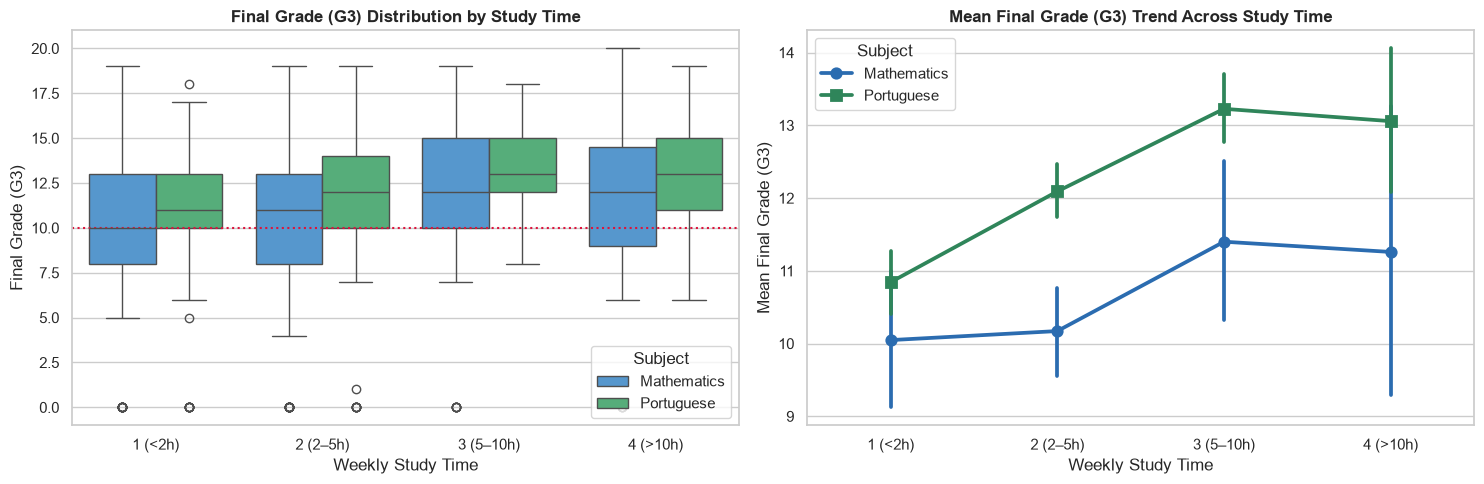

Saved: 05_studytime_vs_final_grade.png


count   mean  median
Subject     studytime                      
Mathematics 1            105  10.05    10.0
            2            198  10.17    11.0
            3             65  11.40    12.0
            4             27  11.26    12.0
Portuguese  1            212  10.84    11.0
            2            305  12.09    12.0
            3             97  13.23    13.0
            4             35  13.06    13.0

In [7]:
study_labels = {1: "1 (<2h)", 2: "2 (2–5h)", 3: "3 (5–10h)", 4: "4 (>10h)"}
df_plot["studytime_label"] = df_plot["studytime"].map(study_labels)
order_labels = [study_labels[k] for k in [1, 2, 3, 4]]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: Boxplot by study time & subject
sns.boxplot(data=df_plot, x="studytime_label", y="G3", hue="Subject",
            order=order_labels, palette=["#4299e1", "#48bb78"], ax=axes[0])
axes[0].axhline(10, color="crimson", linestyle=":", linewidth=1.5)
axes[0].set_title("Final Grade (G3) Distribution by Study Time", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Weekly Study Time")
axes[0].set_ylabel("Final Grade (G3)")

# Right: Mean G3 trend with 95% confidence interval
sns.pointplot(data=df_plot, x="studytime_label", y="G3", hue="Subject",
              order=order_labels, palette=["#2b6cb0", "#2f855a"], markers=["o", "s"], ax=axes[1])
axes[1].set_title("Mean Final Grade (G3) Trend Across Study Time", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Weekly Study Time")
axes[1].set_ylabel("Mean Final Grade (G3)")

plt.tight_layout()
study_path = FIGURES_DIR / "05_studytime_vs_final_grade.png"
plt.savefig(study_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {study_path.name}")

display(df_plot.groupby(["Subject", "studytime"])["G3"].agg(["count", "mean", "median"]).round(2))

### Observations — Study Time vs Final Grades (`05_studytime_vs_final_grade.png`)
1. **Clear upward gain up to 5–10 hours/week:** Average `G3` increases from level `1` (`<2h`) to level `3` (`5–10h`) in both courses: `10.05 → 11.40` (`+1.35` points) in Mathematics and `10.84 → 13.23` (`+2.39` points) in Portuguese.
2. **Plateau above 10 hours/week:** At level `4` (`>10h`), average grades level off slightly (`11.26` Math, `13.06` Portuguese) with wider confidence intervals due to smaller sample sizes (`n = 27` Math, `n = 35` Portuguese).
3. **Stronger sensitivity in Portuguese:** Study time correlates more strongly with final grades in Portuguese (`r = 0.25`) than in Mathematics (`r = 0.10`).

## 7. Absences vs Final Grades (`G3`)
We inspect how school absences relate to final grades using both a continuous scatter plot and grouped absence buckets (`0`, `1–5`, `6–15`, `>15`). We also inspect the `G3 = 0` subset to understand an interesting pattern in Mathematics.

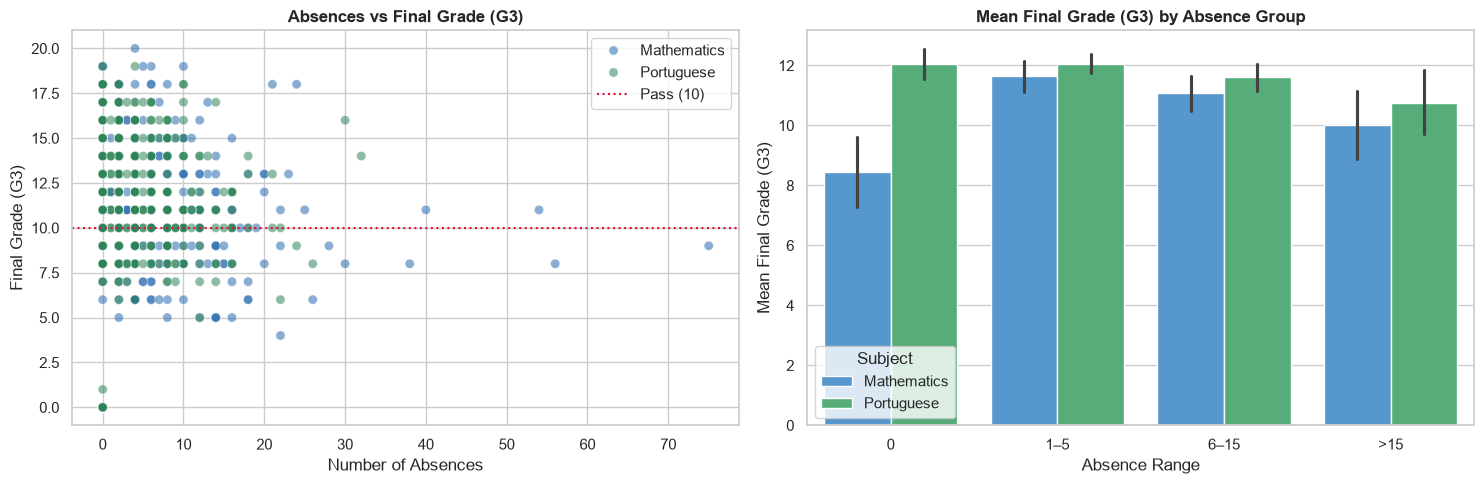

Saved: 06_absences_vs_final_grade.png
Math G3=0 students (38): 38 have absences=0
Portuguese G3=0 students (15): 15 have absences=0


In [8]:
bins = [-1, 0, 5, 15, 100]
bin_labels = ["0", "1–5", "6–15", ">15"]
df_plot["absence_group"] = pd.cut(df_plot["absences"], bins=bins, labels=bin_labels)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: Scatter plot of absences vs G3
sns.scatterplot(data=df_plot, x="absences", y="G3", hue="Subject",
                palette=["#2b6cb0", "#2f855a"], alpha=0.55, s=45, ax=axes[0])
axes[0].axhline(10, color="crimson", linestyle=":", linewidth=1.5, label="Pass (10)")
axes[0].set_title("Absences vs Final Grade (G3)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Number of Absences")
axes[0].set_ylabel("Final Grade (G3)")
axes[0].legend()

# Right: Mean G3 by absence bucket
sns.barplot(data=df_plot, x="absence_group", y="G3", hue="Subject",
            order=bin_labels, palette=["#4299e1", "#48bb78"], errorbar=("ci", 95), ax=axes[1])
axes[1].set_title("Mean Final Grade (G3) by Absence Group", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Absence Range")
axes[1].set_ylabel("Mean Final Grade (G3)")

plt.tight_layout()
abs_path = FIGURES_DIR / "06_absences_vs_final_grade.png"
plt.savefig(abs_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {abs_path.name}")

# Inspect why Math 0-absence mean is lower: check absences among G3 == 0 students
math_zero_g3 = df_math[df_math["G3"] == 0]
por_zero_g3 = df_por[df_por["G3"] == 0]
print(f"Math G3=0 students ({len(math_zero_g3)}): {int((math_zero_g3['absences'] == 0).sum())} have absences=0")
print(f"Portuguese G3=0 students ({len(por_zero_g3)}): {int((por_zero_g3['absences'] == 0).sum())} have absences=0")

### Observations — Absences vs Final Grades (`06_absences_vs_final_grade.png`)
1. **Decline from moderate to high absences:** Among students who attended (`1–5`, `6–15`, `>15` absences), mean `G3` drops steadily as absences rise — in Mathematics from `11.65` (`1–5`) down to `10.03` (`>15`), and in Portuguese from `12.06` (`1–5`) down to `10.76` (`>15`).
2. **Why Mathematics `0` absences has a low average (`8.44`):** Every single one of the `38` Math students with `G3 = 0` (`100%`) also has `absences = 0` recorded in the dataset (same for all `15` Portuguese students with `G3 = 0`), pulling down the `0`-absence group mean.
3. **Extreme absence outliers:** A handful of Math students have `30–75` absences (with `max = 75`), while Portuguese absences stay at or below `32`.

## 8. Compare Mathematics vs Portuguese Performance
We summarize the key differences between the two courses across pass rate (`G3 >= 10`), average grade trajectory (`G1 → G2 → G3`), and overall `G3` spread.

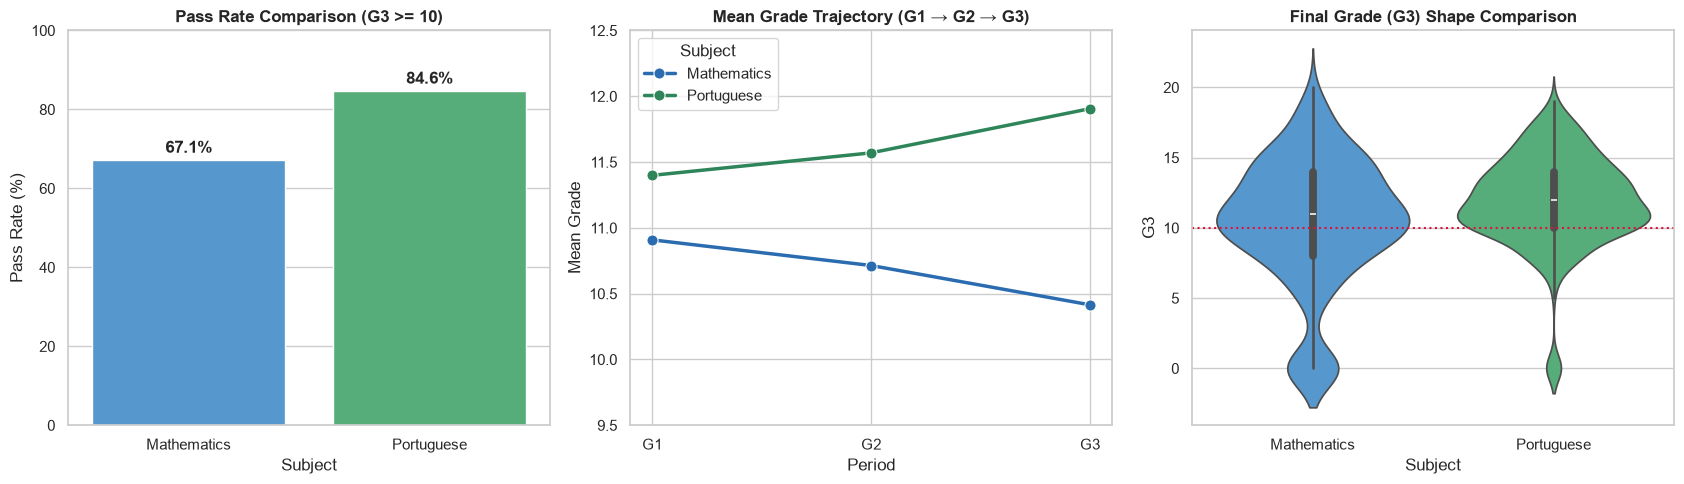

Saved: 07_math_vs_portuguese_comparison.png


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Panel A: Pass Rate comparison
pass_df = pd.DataFrame({
    "Subject": ["Mathematics", "Portuguese"],
    "Pass Rate (%)": [
        (df_math["G3"] >= 10).mean() * 100,
        (df_por["G3"] >= 10).mean() * 100,
    ]
})
bars = sns.barplot(data=pass_df, x="Subject", y="Pass Rate (%)", hue="Subject",
                   palette=["#4299e1", "#48bb78"], legend=False, ax=axes[0])
for container in bars.containers:
    axes[0].bar_label(container, fmt="%.1f%%", padding=3, fontweight="bold")
axes[0].set_ylim(0, 100)
axes[0].set_title("Pass Rate Comparison (G3 >= 10)", fontsize=12, fontweight="bold")

# Panel B: Mean progression G1 -> G2 -> G3
traj_df = pd.DataFrame({
    "Period": ["G1", "G2", "G3", "G1", "G2", "G3"],
    "Mean Grade": [
        df_math["G1"].mean(), df_math["G2"].mean(), df_math["G3"].mean(),
        df_por["G1"].mean(), df_por["G2"].mean(), df_por["G3"].mean(),
    ],
    "Subject": ["Mathematics"] * 3 + ["Portuguese"] * 3
})
sns.lineplot(data=traj_df, x="Period", y="Mean Grade", hue="Subject",
             palette=["#2b6cb0", "#2f855a"], marker="o", linewidth=2.5, markersize=8, ax=axes[1])
axes[1].set_ylim(9.5, 12.5)
axes[1].set_title("Mean Grade Trajectory (G1 → G2 → G3)", fontsize=12, fontweight="bold")

# Panel C: Violin + Boxplot comparison of G3
sns.violinplot(data=df_plot, x="Subject", y="G3", hue="Subject",
               palette=["#4299e1", "#48bb78"], legend=False, inner="box", ax=axes[2])
axes[2].axhline(10, color="crimson", linestyle=":", linewidth=1.5)
axes[2].set_title("Final Grade (G3) Shape Comparison", fontsize=12, fontweight="bold")

plt.tight_layout()
comp_path = FIGURES_DIR / "07_math_vs_portuguese_comparison.png"
plt.savefig(comp_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {comp_path.name}")

### Observations — Mathematics vs Portuguese Comparison (`07_math_vs_portuguese_comparison.png`)
1. **Higher pass rate in Portuguese:** `84.6%` of Portuguese students passed (`G3 >= 10`) compared to `67.1%` in Mathematics (`+17.5` percentage points).
2. **Opposite grade trajectories across the year:** Portuguese average scores improve from `G1` (`11.40`) → `G2` (`11.57`) → `G3` (`11.91`), while Mathematics average scores decline slightly from `G1` (`10.91`) → `G2` (`10.71`) → `G3` (`10.42`), largely influenced by the `38` zero final grades.
3. **Distribution shape:** The violin plot shows a thicker lower tail near `0` in Mathematics, whereas Portuguese is concentrated solidly between `9` and `15`.

## 9. Identify Missing Values and Outliers
We programmatically check missing values across every column and apply the standard **IQR rule** (`< Q1 - 1.5 * IQR` or `> Q3 + 1.5 * IQR`) with NumPy to list and visualize outliers.

In [10]:
def summarize_outliers_iqr(df: pd.DataFrame, subject: str) -> pd.DataFrame:
    """Identify IQR-based outliers across all numeric columns."""
    rows = []
    for col in df.select_dtypes(include=[np.number]).columns:
        values = df[col].to_numpy(dtype=float)
        q1, q3 = np.percentile(values, [25, 75])
        iqr = q3 - q1
        low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_outliers = int(np.sum((values < low) | (values > high)))
        if n_outliers > 0:
            rows.append({
                "Subject": subject,
                "Column": col,
                "Outlier_Count": n_outliers,
                "Pct_of_Rows": round(n_outliers / len(df) * 100, 2),
                "Lower_Bound": round(low, 2),
                "Upper_Bound": round(high, 2),
                "Min_Val": int(values.min()),
                "Max_Val": int(values.max()),
            })
    return pd.DataFrame(rows)


print("Missing values per dataset:")
print(f"  Mathematics: {int(df_math.isnull().sum().sum())} missing cells")
print(f"  Portuguese : {int(df_por.isnull().sum().sum())} missing cells")

outliers_df = pd.concat([
    summarize_outliers_iqr(df_math, "Mathematics"),
    summarize_outliers_iqr(df_por, "Portuguese"),
], ignore_index=True)
display(outliers_df)

Missing values per dataset:
  Mathematics: 0 missing cells
  Portuguese : 0 missing cells


,Subject,Column,Outlier_Count,Pct_of_Rows,Lower_Bound,Upper_Bound,Min_Val,Max_Val
0,Mathematics,age,1,0.25,13.0,21.0,15,22
1,Mathematics,Fedu,2,0.51,0.5,4.5,0,4
2,Mathematics,traveltime,8,2.03,-0.5,3.5,1,4
3,Mathematics,studytime,27,6.84,-0.5,3.5,1,4
4,Mathematics,failures,83,21.01,0.0,0.0,0,3
5,Mathematics,famrel,26,6.58,2.5,6.5,1,5
6,Mathematics,freetime,19,4.81,1.5,5.5,1,5
7,Mathematics,Dalc,18,4.56,-0.5,3.5,1,5
8,Mathematics,absences,15,3.80,-12.0,20.0,0,75
9,Mathematics,G2,13,3.29,3.0,19.0,0,19


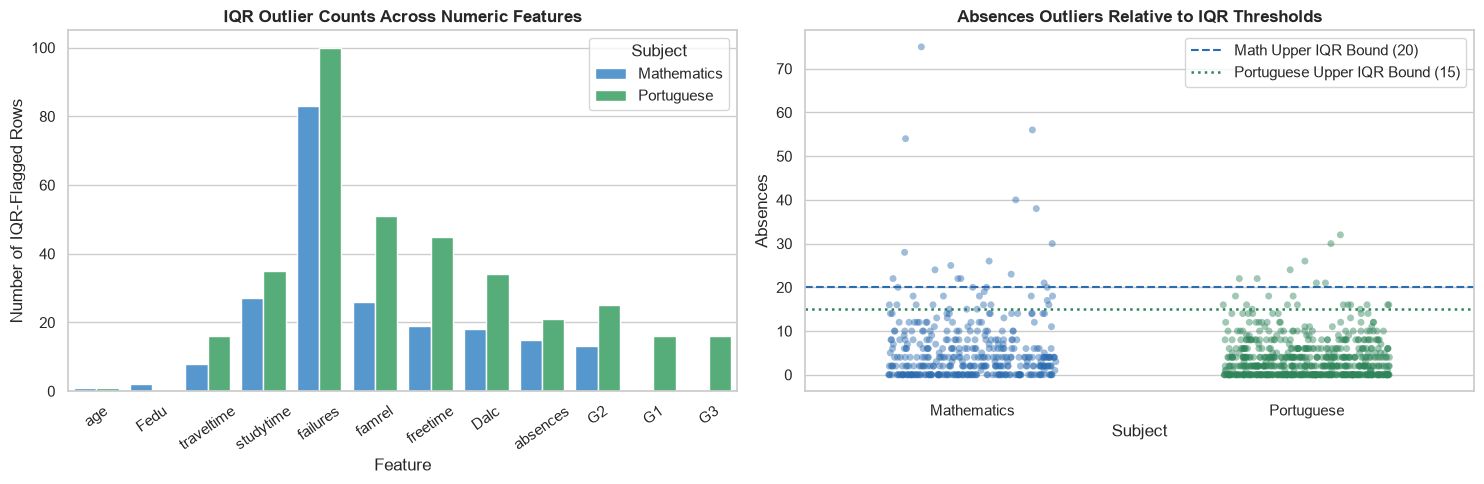

Saved: 08_outliers_overview.png


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: Outlier counts by column and subject
sns.barplot(data=outliers_df, x="Column", y="Outlier_Count", hue="Subject",
            palette=["#4299e1", "#48bb78"], ax=axes[0])
axes[0].set_title("IQR Outlier Counts Across Numeric Features", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Feature")
axes[0].set_ylabel("Number of IQR-Flagged Rows")
axes[0].tick_params(axis="x", rotation=35)

# Right: Zoom on absences with IQR upper bounds highlighted
sns.stripplot(data=df_plot, x="Subject", y="absences", hue="Subject",
              palette=["#2b6cb0", "#2f855a"], legend=False, alpha=0.45, jitter=0.25, ax=axes[1])
axes[1].axhline(20.0, color="#2b6cb0", linestyle="--", linewidth=1.5, label="Math Upper IQR Bound (20)")
axes[1].axhline(15.0, color="#2f855a", linestyle=":", linewidth=1.8, label="Portuguese Upper IQR Bound (15)")
axes[1].set_title("Absences Outliers Relative to IQR Thresholds", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Subject")
axes[1].set_ylabel("Absences")
axes[1].legend()

plt.tight_layout()
out_path = FIGURES_DIR / "08_outliers_overview.png"
plt.savefig(out_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {out_path.name}")

### Observations — Missing Values and Outliers (`08_outliers_overview.png`)
1. **Zero missing values:** Neither `student-mat.csv` nor `student-por.csv` contains any `NaN`/missing cells, so no imputation is required.
2. **True extreme numeric outliers (`absences`):** `absences` has genuine extreme upper outliers — `15` students above `20` in Math (reaching `75`) and `21` students above `15` in Portuguese (reaching `32`). In later modeling, tree-based models handle these naturally, while linear/neural models may benefit from scaling or capping/log-transforming `absences`.
3. **Structural/scale-induced IQR flags:** Features like `failures` (`>0`), `studytime` (`=4`), `Dalc` (`>=4`), and `famrel` (`<=2`) are flagged by the mechanical IQR rule simply because their distributions are tightly concentrated on `1–2` integer values — these are valid domain categories rather than data errors.
4. **Zero final grade (`G3 = 0`) anomalies:** `38` Math students and `15` Portuguese students have `G3 = 0` paired with `absences = 0`; these should be examined carefully when framing regression vs pass/fail classification.